In [1]:
%load_ext autoreload
%autoreload 2

import json
import os
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as sig
from tqdm import tqdm

from entrained_gamma import *

PATH_TO_DATA = Path('data/PooledData')
DIRECTORY = "figures/pooled_data"
os.makedirs(DIRECTORY, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['figure.figsize'] = (16, 9)
mpl.rcParams['font.family'] = 'Arial'

# Entrained gamma, pooled data

### Loading data

In [2]:
# LOAD JSONS
# recursively searches for any json file in the data directory
files = sorted(PATH_TO_DATA.rglob("*.json"))

recs = []
skipped = 0
for path in tqdm(files):
    with open(path, "r") as f:
        try:
            recs.append(json.load(f))
        except json.decoder.JSONDecodeError:
            print(f"Failed to load {path}. Skipping...")
            recs.append({})
            skipped += 1
print(f"{len(files)-skipped}/{len(files)} files loaded successfully.")
master_df = pd.DataFrame(recs).dropna(subset='SessionDate')

master_df.info()

 11%|█         | 94/881 [00:00<00:03, 211.93it/s]

Failed to load data/PooledData/sub-020/ses-2025-09-24_1236/Report_Json_Session_Report_20250924T084428[1].json. Skipping...


100%|██████████| 881/881 [00:07<00:00, 111.23it/s]

880/881 files loaded successfully.
<class 'pandas.DataFrame'>
Index: 880 entries, 0 to 880
Data columns (total 40 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   DataVersion                     845 non-null    str   
 1   AbnormalEnd                     880 non-null    object
 2   FullyReadForSession             677 non-null    object
 3   ReadAllStatus                   644 non-null    str   
 4   FeatureInformationCode          880 non-null    str   
 5   SessionDate                     880 non-null    str   
 6   SessionEndDate                  880 non-null    str   
 7   ProgrammerTimezone              880 non-null    str   
 8   ProgrammerTimezoneId            847 non-null    str   
 9   ProgrammerUtcOffset             880 non-null    str   
 10  ProgrammerLocale                880 non-null    str   
 11  ProgrammerVersion               880 non-null    str   
 12  PatientInformation             

In [3]:
df = master_df.copy()

# interpret the file path to get patient, visit, and report name
stems = pd.Series([str(p.relative_to(PATH_TO_DATA)) for p in files], name="stem")
df.insert(0, 'patient', '')
df.insert(1, 'visit', '')
df.insert(2, 'report', '')
df[['patient', 'visit', 'report']] = stems.str.split('/', expand=True)

# add a column for diagnosis
df.insert(3, 'diagnosis', pd.json_normalize(master_df.PatientInformation)['Initial.Diagnosis'])
df.diagnosis = df.diagnosis.str.extract(r'Def\.(.+)$', expand=False) # only keep the stuff after Def.

# and another for the lead locations
def get_lead_locations(d:list[dict])->dict[str, str]:
    out = {'L': '', 'R': ''}
    for row in d:
        if 'Left' in row['Hemisphere']:
            out['L'] = row['LeadLocation'].split('.')[1]
        elif 'Right' in row['Hemisphere']:
            out['R'] = row['LeadLocation'].split('.')[1]
    return out
df.insert(4, 'implant_location', master_df.LeadConfiguration.map(lambda d: get_lead_locations(d['Initial'])))

# filter the columns to keep only those that are relevant for analysis
df = df.filter(regex='patient|visit|diag|^imp|^Session|^Groups$|^Brain')
df = df.join(
    pd.json_normalize(
        # sometimes DiagnosticData is empty so we make it {} to work with json_normalize
        master_df.DiagnosticData.map(lambda x: x if isinstance(x, dict) else {}),
        max_level=1,
    ).add_prefix("DiagnosticData.")
)
df[['SessionDate', 'SessionEndDate']] = df[['SessionDate', 'SessionEndDate']].apply(pd.to_datetime)

df.info()

<class 'pandas.DataFrame'>
Index: 880 entries, 0 to 880
Data columns (total 20 columns):
 #   Column                                                       Non-Null Count  Dtype              
---  ------                                                       --------------  -----              
 0   patient                                                      880 non-null    str                
 1   visit                                                        880 non-null    str                
 2   diagnosis                                                    880 non-null    str                
 3   implant_location                                             880 non-null    object             
 4   SessionDate                                                  880 non-null    datetime64[us, UTC]
 5   SessionEndDate                                               830 non-null    datetime64[us, UTC]
 6   Groups                                                       880 non-null    object       

### BrainSenseLFP

In [4]:
# PARSE OUT BRAIN SENSE LFP DATA
blfp = df[["patient", "visit", "SessionDate", "BrainSenseLfp"]].copy()

# 1. Explode the Brainsense LFP column into individual recordings
blfp = blfp.dropna()
blfp.BrainSenseLfp = blfp.BrainSenseLfp.map(lambda x: x if isinstance(x, list) else [x])
blfp = blfp.explode("BrainSenseLfp").reset_index(drop=True)
norm = pd.json_normalize(blfp.BrainSenseLfp, max_level=0)
blfp = pd.concat([blfp.drop(columns="BrainSenseLfp"), norm], axis=1)

# 2. conv. date times to datetime
blfp["FirstPacketDateTime"] = blfp.FirstPacketDateTime.map(pd.to_datetime)

# 3. explode channel column again to get one row per hemisphere
blfp.Channel = blfp.Channel.str.split(",")
blfp = blfp.explode("Channel").reset_index(drop=True)
hemisphere = blfp.Channel.str.extract(r"_(LEFT|RIGHT)$", expand=False).map(
    {"LEFT": "Left", "RIGHT": "Right"}
)

# 4. get hemisphere-specific parameters from TherapySnapshot
params = pd.Series([d.get(k) for d, k in zip(blfp.TherapySnapshot, hemisphere)])
params = pd.json_normalize(params, max_level=0)
PARAM_COLS = [
    "StreamingAdaptiveMode",
    "AdaptiveTherapyStatus",
    "PulseWidthInMicroSecond",
    "RateInHertz",
    "LowerLimitInMilliAmps",
    "UpperLimitInMilliAmps",
    "FrequencyInHertz",
]

blfp = pd.concat([blfp, params[PARAM_COLS]], axis=1)

# 5. get stimulation time, global sequences, and LFP data from LfpData
lfp_data = [pd.json_normalize(x, max_level=0) for x in blfp.LfpData]
blfp['stim_time_ms'] = [df.TicksInMs.to_numpy() for df in lfp_data]
blfp['GlobalSequences'] = [df.Seq.unique() for df in lfp_data]

settings = [pd.json_normalize(df[h]) for df, h in zip(lfp_data, hemisphere)]
blfp['stim_mA'] = [df.mA.to_numpy() for df in settings]
blfp['LFP'] = [df.LFP.to_numpy() for df in settings]
blfp = blfp.drop(columns=["LfpData", "TherapySnapshot"])

blfp.info()

<class 'pandas.DataFrame'>
RangeIndex: 1772 entries, 0 to 1771
Data columns (total 19 columns):
 #   Column                              Non-Null Count  Dtype              
---  ------                              --------------  -----              
 0   patient                             1772 non-null   str                
 1   visit                               1772 non-null   str                
 2   SessionDate                         1772 non-null   datetime64[us, UTC]
 3   Channel                             1772 non-null   str                
 4   FirstPacketDateTime                 1772 non-null   datetime64[us, UTC]
 5   FirstPacketDateTimeBlockId          1560 non-null   float64            
 6   FirstPacketDateTimeOffsetInSeconds  1560 non-null   float64            
 7   SampleRateInHz                      1772 non-null   int64              
 8   StreamingAdaptiveMode               1552 non-null   str                
 9   AdaptiveTherapyStatus               1552 non-null   

### BrainSenseTimeDomain

In [ ]:
# The BSTD column is originally lists of samples per patient, explode+normalize to get one sample per row
bstd = df[["patient", "visit", "diagnosis", "implant_location", "SessionDate", "BrainSenseTimeDomain"]].copy()
bstd = bstd.dropna()
bstd.BrainSenseTimeDomain = bstd.BrainSenseTimeDomain.map(lambda x: x if isinstance(x, list) else [x])
bstd = bstd.explode("BrainSenseTimeDomain").reset_index(drop=True)
norm = pd.json_normalize(bstd.BrainSenseTimeDomain)
bstd = pd.concat([bstd.drop(columns="BrainSenseTimeDomain"), norm], axis=1)

# Parse string data into their appropriate types
bstd.TimeDomainData = bstd.TimeDomainData.map(np.array)
bstd["FirstPacketDateTime"] = pd.to_datetime(bstd.FirstPacketDateTime)
LIST_FIELDS = ["GlobalSequences", "GlobalPacketSizes", "TicksInMses"]
bstd[LIST_FIELDS] = bstd[LIST_FIELDS].map(
    # convert comma-separated strings to lists of integers
    lambda s: [int(i) for i in s.split(",") if i.isnumeric()]
)

# Check for weird length mismatches and drop those samples
for sample in bstd.itertuples():
    if sum(sample.GlobalPacketSizes) != len(sample.TimeDomainData):
        print(
            f"Recording {sample.Index} (from {sample.patient}_{sample.visit} "
            f"channel {sample.Channel}) has inconsistent lengths, dropping."
        )
        bstd = bstd.drop(sample.Index)

# Use method from user guide to get time vector for each sample
bstd["time_ms"] = bstd.apply(get_time_BSTD, axis=1)

# Filter to only include samples with duration > 3 seconds
# to make tolerance of 2 seconds in merge_asof safe
dur_s = (bstd.time_ms.str[-1] - bstd.time_ms.str[0])/1000 + 1/bstd.SampleRateInHz
bstd = bstd[dur_s > 3]

# JOIN IN BLFP TO GET SETTINGS
JOIN_COLS = [ # columns in blfp to keep for join
    "patient",
    "visit",
    "Channel",
    "FirstPacketDateTime",
    "stim_mA",
    "stim_time_ms",
    "LFP",
] + PARAM_COLS

left = bstd.sort_values("FirstPacketDateTime")
right = blfp.sort_values("FirstPacketDateTime")
bstd = pd.merge_asof(
    left,
    right[JOIN_COLS],
    on="FirstPacketDateTime",
    by=["patient", "visit", "Channel"],
    direction="nearest",
    tolerance=pd.Timedelta("2s"),
)
bstd = bstd.sort_values(
    ["patient", "FirstPacketDateTime", "Channel"]
).reset_index(drop=True)

# # Separate out discontinuous segments into separate rows
bstd = bstd.dropna(subset=['stim_mA'])
bstd['original_sample'] = bstd.index
bstd = pd.concat(bstd.apply(separate_disconts, axis=1).to_list(), ignore_index=True)

# Get duration of each separated sample in seconds
bstd['duration_s'] = (bstd.time_ms.str[-1] - bstd.time_ms.str[0])/1000 + 1/bstd.SampleRateInHz

# Make sure the duration makes sense with packet sizes once again
assert np.all(
    np.abs(bstd.GlobalPacketSizes.map(sum) / bstd.SampleRateInHz / bstd.duration_s - 1)
    < 1e-3
), (
    "duration_s should be equal to the sum of GlobalPacketSizes divided by SampleRateInHz"
)

bstd.insert(1, 'FirstPacketDateTime', bstd.pop('FirstPacketDateTime'))  # move FirstPacketDateTime to second column
bstd.insert(2, 'Channel', bstd.pop('Channel'))  # move Channel to third column


bstd.info()

Recording 1328 (from sub-165_Stordahl_2024-10-15T12:56:14Z.json channel ZERO_THREE_LEFT) has inconsistent lengths, dropping.
Recording 1344 (from sub-165_Stordahl_20241015.json channel ZERO_THREE_LEFT) has inconsistent lengths, dropping.
Recording 1391 (from sub-169_Ross-Biddle_2024-10-23T18:39:12Z.json channel ONE_THREE_LEFT) has inconsistent lengths, dropping.
Recording 1505 (from sub-196_Webster_20250121.json channel ONE_THREE_RIGHT) has inconsistent lengths, dropping.
<class 'pandas.DataFrame'>
RangeIndex: 1957 entries, 0 to 1956
Data columns (total 29 columns):
 #   Column                              Non-Null Count  Dtype              
---  ------                              --------------  -----              
 0   patient                             1957 non-null   str                
 1   FirstPacketDateTime                 1957 non-null   datetime64[us, UTC]
 2   Channel                             1957 non-null   str                
 3   visit                               1

In [ ]:
# SAVE BSTD
# bstd.to_csv(f"{DIRECTORY}/brainsensetimedomain.csv")
bstd_filt = bstd[(bstd.duration_s > 20)].drop(columns='original_sample').reset_index(drop=True)
bstd_filt['rec'] = bstd_filt.groupby('patient').cumcount()

bstd_abridged = bstd_filt.filter(
    regex="pat|^First.+Time$|Chan|dur|Rate|diag|impl|Width|rec"
).iloc[:, [0, 3, 4, 1, 2, -2, -4, -3, -5, -1]]
bstd_abridged.insert(6, 'stim_min_mA', bstd_filt.stim_mA.map(min))
bstd_abridged.insert(7, 'stim_max_mA', bstd_filt.stim_mA.map(max))
# bstd_abridged.to_csv(f"{DIRECTORY}/recordings.csv", index=False, date_format="%m/%d/%y %H:%M")

bstd_abridged.columns

Index(['patient', 'diagnosis', 'implant_location', 'FirstPacketDateTime',
       'Channel', 'duration_s', 'stim_min_mA', 'stim_max_mA',
       'PulseWidthInMicroSecond', 'RateInHertz', 'SampleRateInHz', 'rec'],
      dtype='str')

### Plotting and saving

In [21]:
def plot_sample(sample: pd.Series, vmin=-40, vmax=10):
    """
    Plot a BrainSenseTimeDomain sample with its time-domain signal, spectrogram, and stimulation current.
    """
    recid = sample.name if isinstance(sample, pd.Series) else sample.Index

    time = (sample.time_ms - sample.time_ms[0]) / 1000  # convert to seconds, relative to the first sample
    time_stim = (sample.stim_time_ms - sample.time_ms[0]) / 1000 # same for stim times
    xlim = (0, time[-1])

    aliased_stim_freq = np.abs(
        sample.SampleRateInHz
        - sample.RateInHertz * np.floor(sample.RateInHertz / sample.SampleRateInHz + 0.5)
    )

    fig = plt.figure(layout="constrained")
    gs = fig.add_gridspec(2, 2)
    ax = [fig.add_subplot(i) for i in [gs[0, 0], gs[0, 1], gs[1, :]]]

    fig.suptitle(
        f"{sample.patient} on {sample.SessionDate.date()} {sample.FirstPacketDateTime.strftime('%H:%M:%S')} (rec {recid})\n"
        f"$diagnosis$ {sample.diagnosis}, $implant\\ location$ {sample.implant_location}\n"
        f"$channel$ {sample.Channel}; {sample.PulseWidthInMicroSecond} µs, {sample.RateInHertz} Hz",
        fontsize=16
    )
    plt.sca(ax[0])
    plt.plot(time, sample.TimeDomainData, lw=1, c="0.8")
    plt.gca().set(xlabel='time (s)', ylabel="voltage (µV)", xlim=xlim, title='time domain')

    plt.sca(ax[1])
    f, Pxx = sig.welch(sample.TimeDomainData, fs=sample.SampleRateInHz)
    plt.plot(f, 10*np.log10(Pxx), c='k')
    plt.axvline(sample.RateInHertz/2, ls="--", c="r", lw=0.5, label="1:2 eFTG")
    plt.axvline(aliased_stim_freq, ls="--", c="m", lw=0.5, label="Aliased stim freq")
    plt.gca().set(xlabel='frequency (Hz)', ylabel='psd (dB rel. to 1 µV²/Hz)', title='power spectral density')
    plt.legend()

    plt.sca(ax[2])
    plot_spectrogram(
        sample.TimeDomainData, fs=sample.SampleRateInHz, nperseg=125, noverlap=None,
        vmin=vmin, vmax=vmax, shading="nearest", cmap='viridis'
    )
    plt.axhline(sample.RateInHertz/2, ls="--", c="w", lw=0.5, label="1:2 eFTG")
    plt.axhline(aliased_stim_freq, ls="--", c="m", lw=0.5, label="Aliased stim freq")
    plt.legend(labelcolor="w")
    plt.gca().set(xlabel="time (s)", ylabel="frequency (Hz)", xlim=xlim, title='spectrogram')

    plt.sca(plt.gca().twinx())
    plt.plot(time_stim, sample.stim_mA, lw=1.5, c="r")
    plt.ylabel("stimulation current (mA)")
    plt.ylim(0, None)
    plt.grid(False)

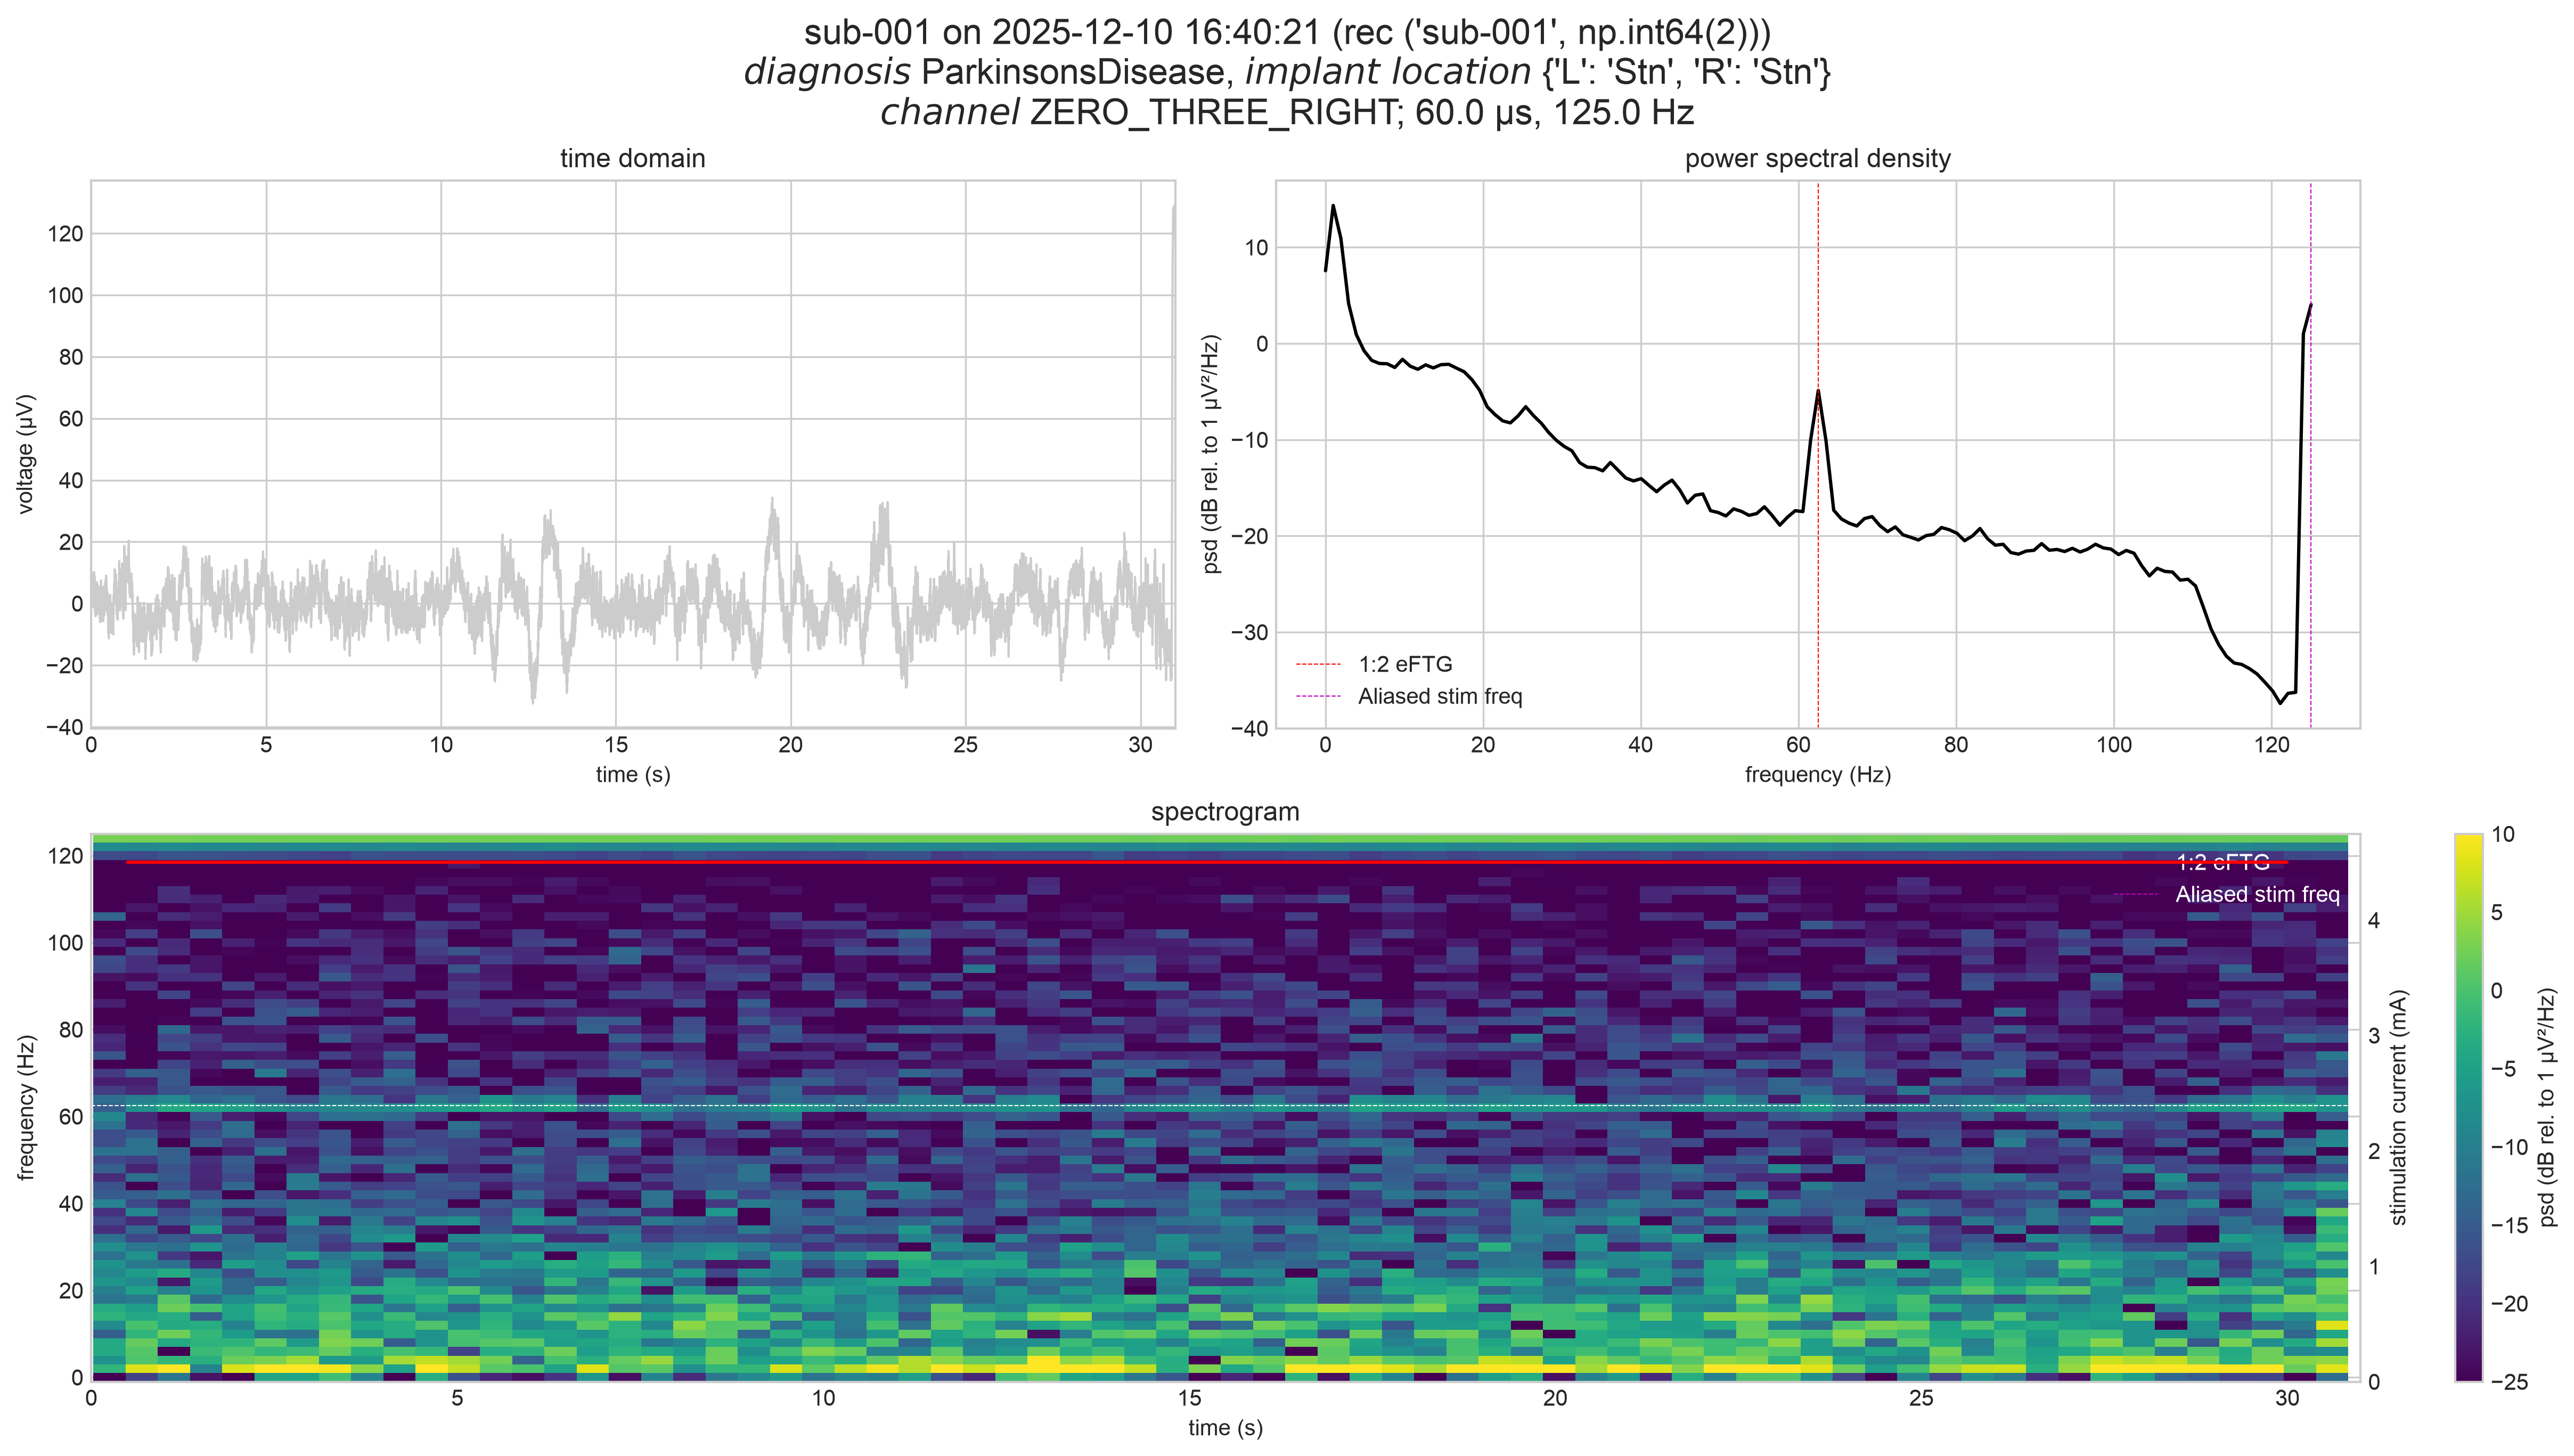

In [28]:
bstd_plot = bstd_filt.set_index(['patient', 'rec'], drop=False)
rec = bstd_plot.loc[('sub-001', 2)].copy(deep=True)
# rec.stim_mA = rec.stim_mA * 0
plot_sample(rec, vmin=-25, vmax=10)

In [29]:
# save
SAVE_FIGS = True

if SAVE_FIGS:
    bstd_save = bstd_filt.set_index('patient')
    patients = bstd_save.index.unique()
    for patient in tqdm(patients, desc="plotting patients"):
        os.makedirs(f"{DIRECTORY}/{patient}", exist_ok=True)
        patient_samples = bstd_save.loc[[patient]].reset_index(names='patient')

        for sample in patient_samples.itertuples():
            plot_sample(sample, vmin=-25, vmax=10)
            filename = (
                f"{DIRECTORY}/{patient}/{patient}_"
                f"{sample.FirstPacketDateTime.strftime('%Y-%m-%dT%H:%M')}_ch{sample.Channel}_rec{sample.Index}.png"
            )
            plt.savefig(filename, pad_inches="layout")
            plt.close()

plotting patients:   4%|▎         | 2/57 [00:13<06:00,  6.55s/it]/var/folders/13/4ntxcq_x1jn9zqt0l3s8l1vw0000gn/T/ipykernel_81102/1427469062.py:17: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(filename, pad_inches="layout")
plotting patients: 100%|██████████| 57/57 [14:50<00:00, 15.63s/it]
